In [ ]:
import os
import numpy as np
import cv2
import matplotlib.pyplot as plt
import seaborn as sns
from zipfile import ZipFile
from skimage.feature import hog, local_binary_pattern
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score
from tensorflow.keras.preprocessing.image import load_img, img_to_array

In [ ]:
# Step 1: Unzip and Load the Dataset
zip_file_path = "/content/archive (16).zip"
extract_to = "dataset_dataset"

with ZipFile(zip_file_path, 'r') as zip_ref:
    zip_ref.extractall(extract_to)

data_dir = "/content/dataset_dataset/Train_Test_Valid"
image_size = (128, 128)
image_data = []
image_features = []
image_labels = []
image_paths = []

# Feature Extraction Function
def extract_features(image_path):
    img = load_img(image_path, target_size=image_size, color_mode="grayscale")
    img_array = img_to_array(img).astype(np.uint8).squeeze()

    # HOG Features
    hog_features, _ = hog(img_array, pixels_per_cell=(8, 8), cells_per_block=(2, 2), visualize=True)

    # LBP Features
    lbp = local_binary_pattern(img_array, P=8, R=1, method="uniform")
    lbp_hist, _ = np.histogram(lbp.ravel(), bins=np.arange(0, 11), density=True)

    # Color Histograms (Using Original Color Image)
    img_color = load_img(image_path, target_size=image_size)
    img_color_array = img_to_array(img_color).astype(np.uint8)
    hist_r = cv2.calcHist([img_color_array], [0], None, [32], [0, 256])
    hist_g = cv2.calcHist([img_color_array], [1], None, [32], [0, 256])
    hist_b = cv2.calcHist([img_color_array], [2], None, [32], [0, 256])

    return np.hstack([hog_features, lbp_hist, hist_r.squeeze(), hist_g.squeeze(), hist_b.squeeze()])

In [ ]:
# Step 2: Load and Process Images
subdirectories = [subdir for subdir in os.listdir(data_dir) if os.path.isdir(os.path.join(data_dir, subdir))]

for subdir in subdirectories:
    subdir_path = os.path.join(data_dir, subdir)
    for class_name in os.listdir(subdir_path):
        class_path = os.path.join(subdir_path, class_name)
        if os.path.isdir(class_path):
            for image_file in os.listdir(class_path):
                if image_file.lower().endswith(('.png', '.jpg', '.jpeg')):
                    image_path = os.path.join(class_path, image_file)
                    try:
                        img = load_img(image_path, target_size=image_size)
                        img_array = img_to_array(img)  # No flatten()

                        image_data.append(img_array)
                        image_paths.append((image_path, class_name))

                        features = extract_features(image_path)
                        image_features.append(features)
                        image_labels.append(class_name)
                    except Exception as e:
                        print(f"Skipping {image_file}: {e}")

image_data = np.array(image_data)
image_features = np.array(image_features)
image_labels = np.array(image_labels)

In [ ]:
# Step 3: Normalize Features & Apply PCA
scaler = StandardScaler()
image_features_scaled = scaler.fit_transform(image_features)

pca = PCA(0.80)
image_data_pca = pca.fit_transform(image_features_scaled)

# Step 4: Clustering
num_clusters = 5

# K-Means Clustering
kmeans = KMeans(n_clusters=num_clusters, random_state=42)
kmeans_labels = kmeans.fit_predict(image_data_pca)

# Agglomerative Clustering
agglo = AgglomerativeClustering(n_clusters=num_clusters)
agglo_labels = agglo.fit_predict(image_data_pca)

In [ ]:
# Step 5: Train SVM Classifier
svm = SVC(kernel='rbf', C=5, gamma='scale')
svm.fit(image_features_scaled, image_labels)

SVC(C=5)

In [ ]:
# Step 6: Classification Accuracy
predicted_labels = svm.predict(image_features_scaled)
accuracy = accuracy_score(image_labels, predicted_labels)
print(f"Classification Accuracy: {accuracy:.4f}")

Classification Accuracy: 1.0000


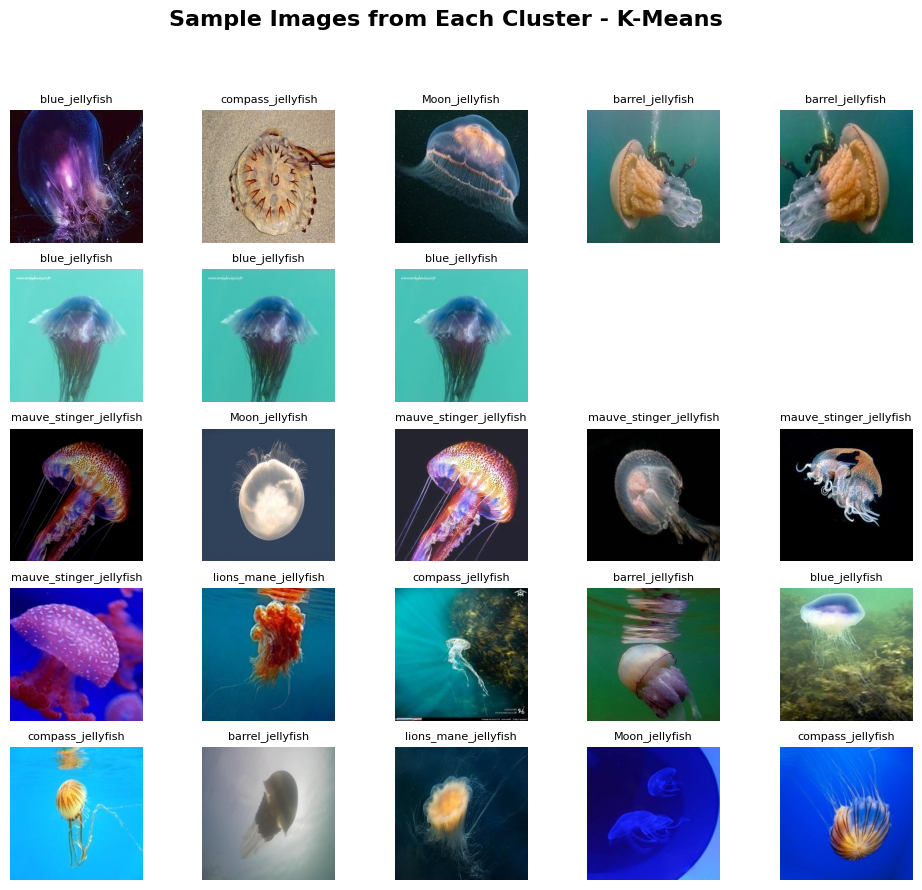

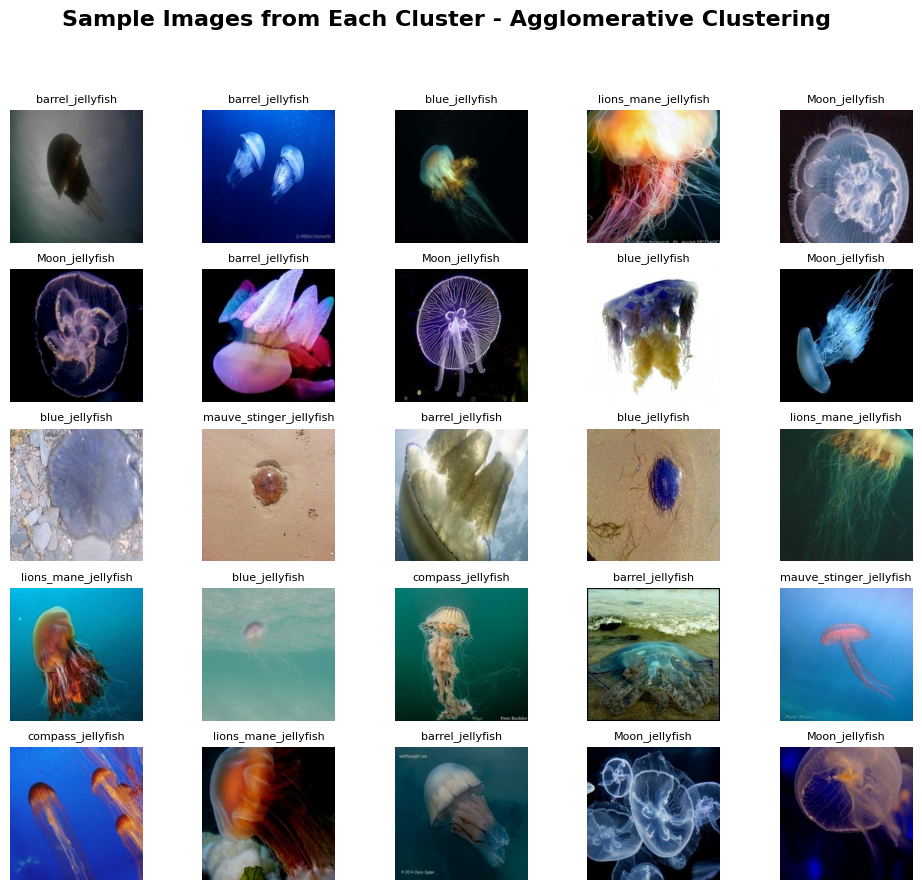

In [ ]:
# Step 7: Visualizing Clustering
def plot_sample_images(cluster_labels, image_paths, num_samples=5, clustering_method="Clustering"):
    plt.figure(figsize=(12, num_clusters * 2))
    for cluster in range(num_clusters):
        cluster_indices = np.where(cluster_labels == cluster)[0]
        selected_indices = np.random.choice(cluster_indices, min(num_samples, len(cluster_indices)), replace=False)
        for i, idx in enumerate(selected_indices):
            plt.subplot(num_clusters, num_samples, cluster * num_samples + i + 1)
            img = load_img(image_paths[idx][0])
            plt.imshow(img)
            plt.axis('off')
            plt.title(image_paths[idx][1], fontsize=8)
            if i == 0:
                plt.ylabel(f'Cluster {cluster}', fontsize=12, fontweight='bold')
    plt.suptitle(f"Sample Images from Each Cluster - {clustering_method}", fontsize=16, fontweight='bold')
    plt.show()

plot_sample_images(kmeans_labels, image_paths, clustering_method="K-Means")
plot_sample_images(agglo_labels, image_paths, clustering_method="Agglomerative Clustering")

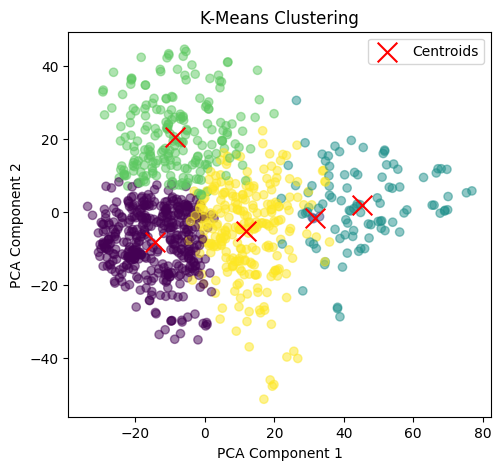

In [ ]:
# Visualizing Clustering in PCA Space
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.scatter(image_data_pca[:, 0], image_data_pca[:, 1], c=kmeans_labels, cmap='viridis', alpha=0.5)
plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1], c='red', marker='x', s=200, label="Centroids")
plt.title("K-Means Clustering")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.legend()

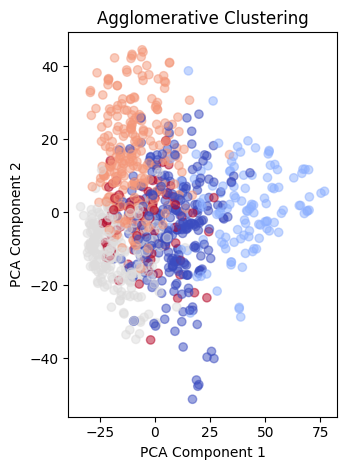

In [ ]:
plt.subplot(1, 2, 2)
plt.scatter(image_data_pca[:, 0], image_data_pca[:, 1], c=agglo_labels, cmap='coolwarm', alpha=0.5)
plt.title("Agglomerative Clustering")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")

plt.tight_layout()
plt.show()

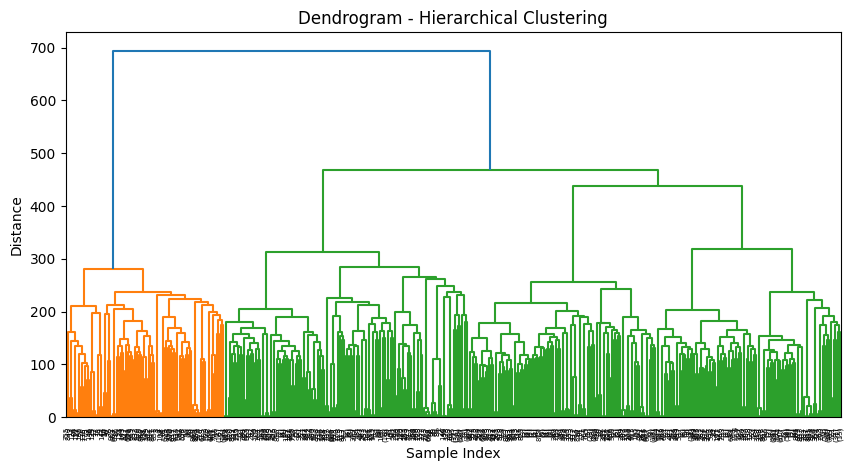

In [ ]:
# Dendrogram for Hierarchical Clustering
plt.figure(figsize=(10, 5))
linked = linkage(image_data_pca, method='ward')
dendrogram(linked, truncate_mode='level', p=10)
plt.title("Dendrogram - Hierarchical Clustering")
plt.xlabel("Sample Index")
plt.ylabel("Distance")
plt.show()

In [ ]:
!pip install kneed

Optimal number of clusters (Elbow Method): 5
Best number of clusters (Silhouette Score): 2 with score 0.0932
Silhouette Score for K-Means: 0.1217
Silhouette Score for Agglomerative Clustering: 0.1318
Best Clustering Method: Agglomerative Clustering


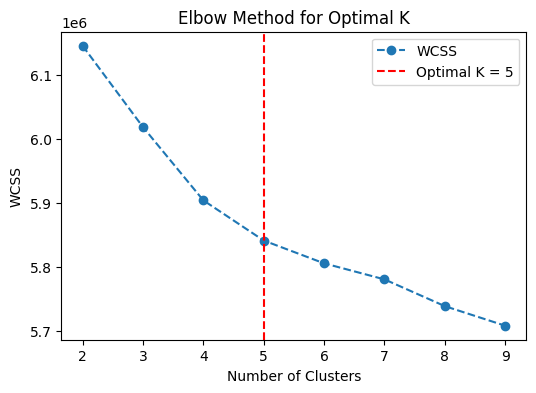

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from kneed import KneeLocator

# Step 1: Compute Silhouette Scores and WCSS for Different K in K-Means
silhouette_scores = []
wcss_values = []
cluster_range = range(2, 10)

for k in cluster_range:
    kmeans_temp = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans_temp.fit_predict(image_data_pca)

    score = silhouette_score(image_data_pca, labels)
    silhouette_scores.append(score)

    wcss_values.append(kmeans_temp.inertia_)

# Step 2: Find Optimal K using the Elbow Method
knee_locator = KneeLocator(cluster_range, wcss_values, curve="convex", direction="decreasing")
optimal_k = knee_locator.knee

# Step 3: Find Best K Based on Silhouette Score
best_k = cluster_range[np.argmax(silhouette_scores)]
best_silhouette = max(silhouette_scores)

# --- Calculate Silhouette Scores for K-Means and Agglomerative Clustering ---
# Use the best_k found from Silhouette Score analysis for both methods
kmeans = KMeans(n_clusters=best_k, random_state=42)
kmeans_labels = kmeans.fit_predict(image_data_pca)
kmeans_silhouette = silhouette_score(image_data_pca, kmeans_labels)

agglo = AgglomerativeClustering(n_clusters=best_k)
agglo_labels = agglo.fit_predict(image_data_pca)
agglo_silhouette = silhouette_score(image_data_pca, agglo_labels)

# Step 4: Compare K-Means and Agglomerative Clustering
best_clustering_method = "K-Means" if kmeans_silhouette > agglo_silhouette else "Agglomerative Clustering"

# Step 5: Display Results
print(f"Optimal number of clusters (Elbow Method): {optimal_k}")
print(f"Best number of clusters (Silhouette Score): {best_k} with score {best_silhouette:.4f}")
print(f"Silhouette Score for K-Means: {kmeans_silhouette:.4f}")
print(f"Silhouette Score for Agglomerative Clustering: {agglo_silhouette:.4f}")
print(f"Best Clustering Method: {best_clustering_method}")

# Step 6: Plot Elbow Method with Highlighted Optimal K
plt.figure(figsize=(6, 4))
plt.plot(cluster_range, wcss_values, marker='o', linestyle='--', label="WCSS")
plt.axvline(x=optimal_k, linestyle="--", color="red", label=f"Optimal K = {optimal_k}")
plt.xlabel("Number of Clusters")
plt.ylabel("WCSS")
plt.title("Elbow Method for Optimal K")
plt.legend()
plt.show()


In [ ]:
# Step 8: Classify a New Image
def classify_new_image(image_path, model, scaler):
    """
    Classifies a new image using the trained SVM model.
    """
    features = extract_features(image_path)
    features_scaled = scaler.transform([features])

    predicted_class = model.predict(features_scaled)[0]
    return predicted_class

new_image_path = "/content/lion mave.jpg"
predicted_class = classify_new_image(new_image_path, svm, scaler)
print(f"The new image belongs to: {predicted_class}")

The new image belongs to: lions_mane_jellyfish
